In [4]:
import os
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf
from keras.layers import Input
from keras.models import Model, Sequential
from keras.layers import Reshape, Dense, Dropout, Flatten, Input, LeakyReLU,BatchNormalization, Conv2DTranspose ,Conv2D ,Embedding, concatenate, CategoryEncoding,Lambda
from keras.datasets import mnist
from keras.optimizers import Adam

In [5]:
gpus = tf.config.experimental.list_physical_devices('GPU')

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled for GPU")
    except RuntimeError as e:
        print(f"Error setting memory growth: {e}")

Memory growth enabled for GPU


In [6]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train = (X_train.astype(np.float32) - 127.5) / 127.5
X_train = np.expand_dims(X_train, axis=-1)

In [7]:
BATCH_SIZE = 128
dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(60000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1783197592.201323   11124 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6005 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1070, pci bus id: 0000:01:00.0, compute capability: 6.1


In [8]:
randomDim = 50
num_classes = 10

In [9]:
# Conditional GAN

In [10]:
# Generator Network
noise_input = Input(shape=(randomDim,), name="noise_input")
label_input = Input(shape=(1,), dtype='int32', name="label_input")

label_embedding = Embedding(num_classes, 50, name="embedding")(label_input)
label_embedding = Flatten(name="flatten")(label_embedding)

combined_input = concatenate([noise_input, label_embedding], name="concatenate_inputs")

x = Dense(7 * 7 * 256)(combined_input)
x = Reshape((7, 7, 256))(x)
x = BatchNormalization()(x)
x = LeakyReLU(0.2)(x)

x = Conv2DTranspose(128, kernel_size=4, strides=2, padding='same')(x)
x = BatchNormalization()(x)
x = LeakyReLU(0.2)(x)

x = Conv2DTranspose(64, kernel_size=4, strides=2, padding='same')(x)
x = BatchNormalization()(x)
x = LeakyReLU(0.2)(x)

output_image = Conv2D(1, kernel_size=3, padding='same', activation='tanh', name="output_image")(x)

generator = Model(inputs=[noise_input, label_input], outputs=output_image, name="conditional_generator")

generator.summary()

Model: "conditional_generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label_input         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 50)     │        500 │ label_input[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ noise_input         │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 50)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_inputs  │ (None, 100)       │          0 │ noise_input[0][0… │
│ (Concatenate)       │                   │            │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 12544)     │  1,266,944 │ concatenate_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 7, 7, 256) │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 7, 7, 256) │      1,024 │ reshape[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 7, 7, 256) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 14, 14,    │    524,416 │ leaky_re_lu[0][0] │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 14,    │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 14, 14,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 28, 28,    │    131,136 │ leaky_re_lu_1[0]… │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        256 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 28, 28,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_image        │ (None, 28, 28, 1) │        577 │ leaky_re_lu_2[0]… │
│ (Conv2D)            │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,925,365 (7.34 MB)

 Trainable params: 1,924,469 (7.34 MB)

 Non-trainable params: 896 (3.50 KB)

In [11]:
num_classes = 10

In [12]:
# Discriminator Network

num_classes = 10
img_shape = (28, 28, 1)

img_input = Input(shape=img_shape, name="image_input")
label_input = Input(shape=(1,), dtype='int32', name="label_input")

one_hot_layer = CategoryEncoding(num_tokens=num_classes, output_mode='one_hot', name="category_encoding")(label_input)

def create_spatial_channels(one_hot_tensor):

    # Shape -> (batch_size, 1, 1, 10)
    reshaped_label = tf.reshape(one_hot_tensor, shape=(-1, 1, 1, num_classes))

    # Shape -> (batch_size, 28, 28, 10)
    return tf.tile(reshaped_label, [1, img_shape[0], img_shape[1], 1])

label_channels_layer = Lambda(create_spatial_channels, name="spatial_tiling")(one_hot_layer)

# Shape -> (None, 28, 28, 11)
combined_input = concatenate([img_input, label_channels_layer], axis=-1)

x = Conv2D(32, kernel_size=3, strides=2, padding='same')(combined_input)
x = LeakyReLU(0.2)(x)

x = Conv2D(64, kernel_size=3, strides=2, padding='same')(x)
x = BatchNormalization()(x)
x = LeakyReLU(0.2)(x)

x = Conv2D(128, kernel_size=3, strides=2, padding='same')(x)
x = BatchNormalization()(x)
x = LeakyReLU(0.2)(x)

x = Flatten()(x)
x = Dropout(0.3)(x)
validity = Dense(1, activation='sigmoid', name="output_validity")(x)

discriminator = Model(inputs=[img_input, label_input], outputs=validity, name="discriminator_onehot_fusion_v2")

discriminator.summary()

Model: "discriminator_onehot_fusion_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label_input         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category_encoding   │ (None, 10)        │          0 │ label_input[0][0] │
│ (CategoryEncoding)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_input         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_tiling      │ (None, 28, 28,    │          0 │ category_encodin… │
│ (Lambda)            │ 10)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 28, 28,    │          0 │ image_input[0][0… │
│ (Concatenate)       │ 11)               │            │ spatial_tiling[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 14, 14,    │      3,200 │ concatenate[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 14, 14,    │          0 │ conv2d[0][0]      │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ leaky_re_lu_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7, 64)  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_4       │ (None, 7, 7, 64)  │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 4, 4, 128) │     73,856 │ leaky_re_lu_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 4, 4, 128) │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_5       │ (None, 4, 4, 128) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 2048)      │          0 │ leaky_re_lu_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_validity     │ (None, 1)         │      2,049 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 98,369 (384.25 KB)

 Trainable params: 97,985 (382.75 KB)

 Non-trainable params: 384 (1.50 KB)

In [13]:
# Train

In [14]:
def plotGeneratedImages(epoch, examples=100, dim=(10, 10), figsize=(10, 10)):
    noise = np.random.normal(0, 1, size=[examples, randomDim])

    num_classes = 10
    sampled_labels = np.array([num for _ in range(examples // num_classes) for num in range(num_classes)])

    generatedImages = generator.predict([noise, sampled_labels])
    generatedImages = generatedImages.reshape(examples, 28, 28)

    plt.figure(figsize=figsize)
    for i in range(generatedImages.shape[0]):
        plt.subplot(dim[0], dim[1], i+1)
        plt.imshow(generatedImages[i], interpolation='nearest', cmap='gray')
        plt.title(f"Digit: {sampled_labels[i]}")
        plt.axis('off')

    plt.tight_layout()
    out_dir = './generated image/cGAN/'
    if not os.path.exists(out_dir):
        os.makedirs(out_dir)
    out = os.path.join(out_dir, 'cGAN_generated_image_epoch_%d.png' % epoch)
    plt.savefig(out)
    plt.close()

In [15]:
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002,beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001,beta_1=0.5)

cross_entropy = tf.keras.losses.BinaryCrossentropy()

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output) * 0.9, real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = real_loss + fake_loss
    return total_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

In [16]:
@tf.function
def train_step(batch):
    images, labels = batch
    batch_size = tf.shape(images)[0]
    gen_loss = tf.constant(0.0)
    disc_loss = tf.constant(0.0)

    for _ in range(2):
        noise_d = tf.random.normal([batch_size, randomDim])
        generated_images_for_disc = generator([noise_d, labels], training=True)

        with tf.GradientTape() as disc_tape:
            real_output = discriminator([images, labels], training=True)
            fake_output_for_disc = discriminator([generated_images_for_disc, labels], training=True)
            d_loss = discriminator_loss(real_output, fake_output_for_disc)

        gradients_of_discriminator = disc_tape.gradient(d_loss, discriminator.trainable_variables)
        discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))
        disc_loss = d_loss


    noise_g = tf.random.normal([batch_size, randomDim])

    with tf.GradientTape() as gen_tape:
        generated_images_for_gen = generator([noise_g, labels], training=True)
        fake_output_for_gen = discriminator([generated_images_for_gen, labels], training=True)
        g_loss = generator_loss(fake_output_for_gen)

    gradients_of_generator = gen_tape.gradient(g_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    gen_loss = g_loss

    return disc_loss, gen_loss

In [17]:
epochs = 200

dLosses = []
gLosses = []

for e in range(1, epochs + 1):
    epoch_d_loss = []
    epoch_g_loss = []

    print('-' * 10, 'Epoch %d' % e, '-' * 10)
    for batch in tqdm(dataset):
        d_loss, g_loss = train_step(batch)

        epoch_d_loss.append(d_loss)
        epoch_g_loss.append(g_loss)

    avg_d_loss = np.mean(epoch_d_loss)
    avg_g_loss = np.mean(epoch_g_loss)

    dLosses.append(avg_d_loss)
    gLosses.append(avg_g_loss)

    print(f"Epoch {e}, Discriminator Loss: {avg_d_loss}, Generator Loss: {avg_g_loss}")

    if e == 1 or e % 10 == 0:
        plotGeneratedImages(e)

---------- Epoch 1 ----------


100%|████████████████████████████████████████████████████████████████████████| 469/469 [00:39<00:00, 11.85it/s]
I0000 00:00:1783197647.515369   11187 service.cc:148] XLA service 0x768db00130c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1783197647.515387   11187 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce GTX 1070, Compute Capability 6.1
2026-07-04 22:40:47.524956: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


Epoch 1, Discriminator Loss: 1.4040157794952393, Generator Loss: 0.9145355820655823


2026-07-04 22:40:47.634297: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:557] Omitted potentially buggy algorithm eng14{} for conv (f32[32,1,28,28]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,64,28,28]{3,2,1,0}, f32[1,64,3,3]{3,2,1,0}, f32[1]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]}
2026-07-04 22:40:47.728741: W external/local_xla/xla/service/gpu/nvptx_compiler.cc:930] The NVIDIA driver's CUDA version is 12.2 which is older than the PTX compiler version 12.5.82. Because the driver is older than the PTX compiler version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward 

1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 485ms/step

...

Epoch 198, Discriminator Loss: 1.360950231552124, Generator Loss: 0.8229964375495911
---------- Epoch 199 ----------


100%|████████████████████████████████████████████████████████████████████████| 469/469 [00:30<00:00, 15.47it/s]


Epoch 199, Discriminator Loss: 1.3620847463607788, Generator Loss: 0.8235217332839966
---------- Epoch 200 ----------


100%|████████████████████████████████████████████████████████████████████████| 469/469 [00:29<00:00, 15.66it/s]


Epoch 200, Discriminator Loss: 1.3613364696502686, Generator Loss: 0.8244579434394836
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


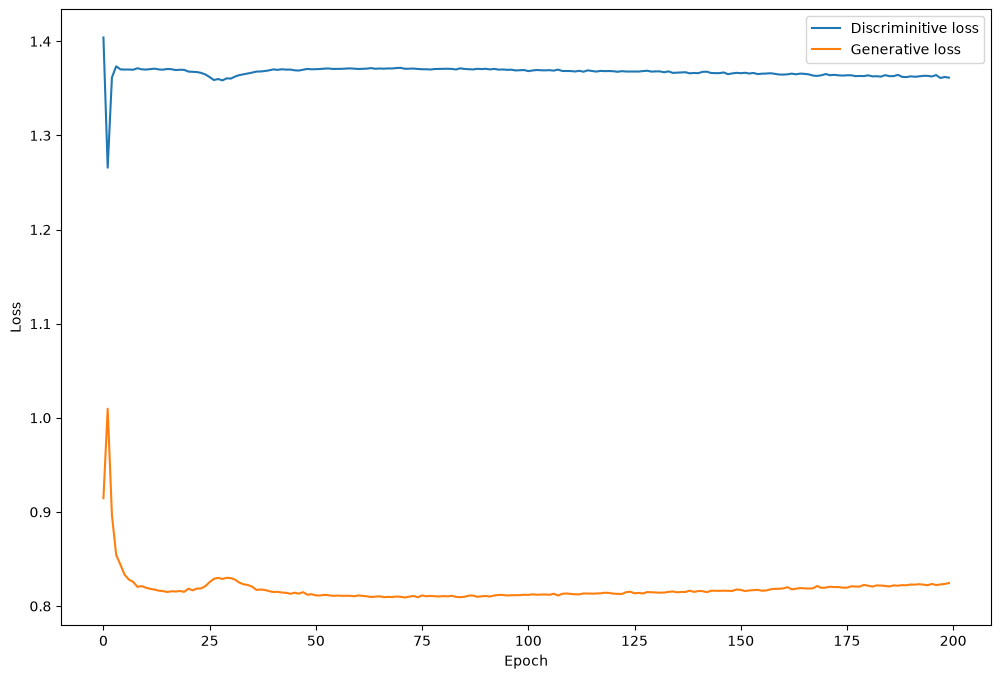

In [18]:
plt.figure(figsize=(12, 8))
plt.plot(dLosses, label='Discriminitive loss')
plt.plot(gLosses, label='Generative loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


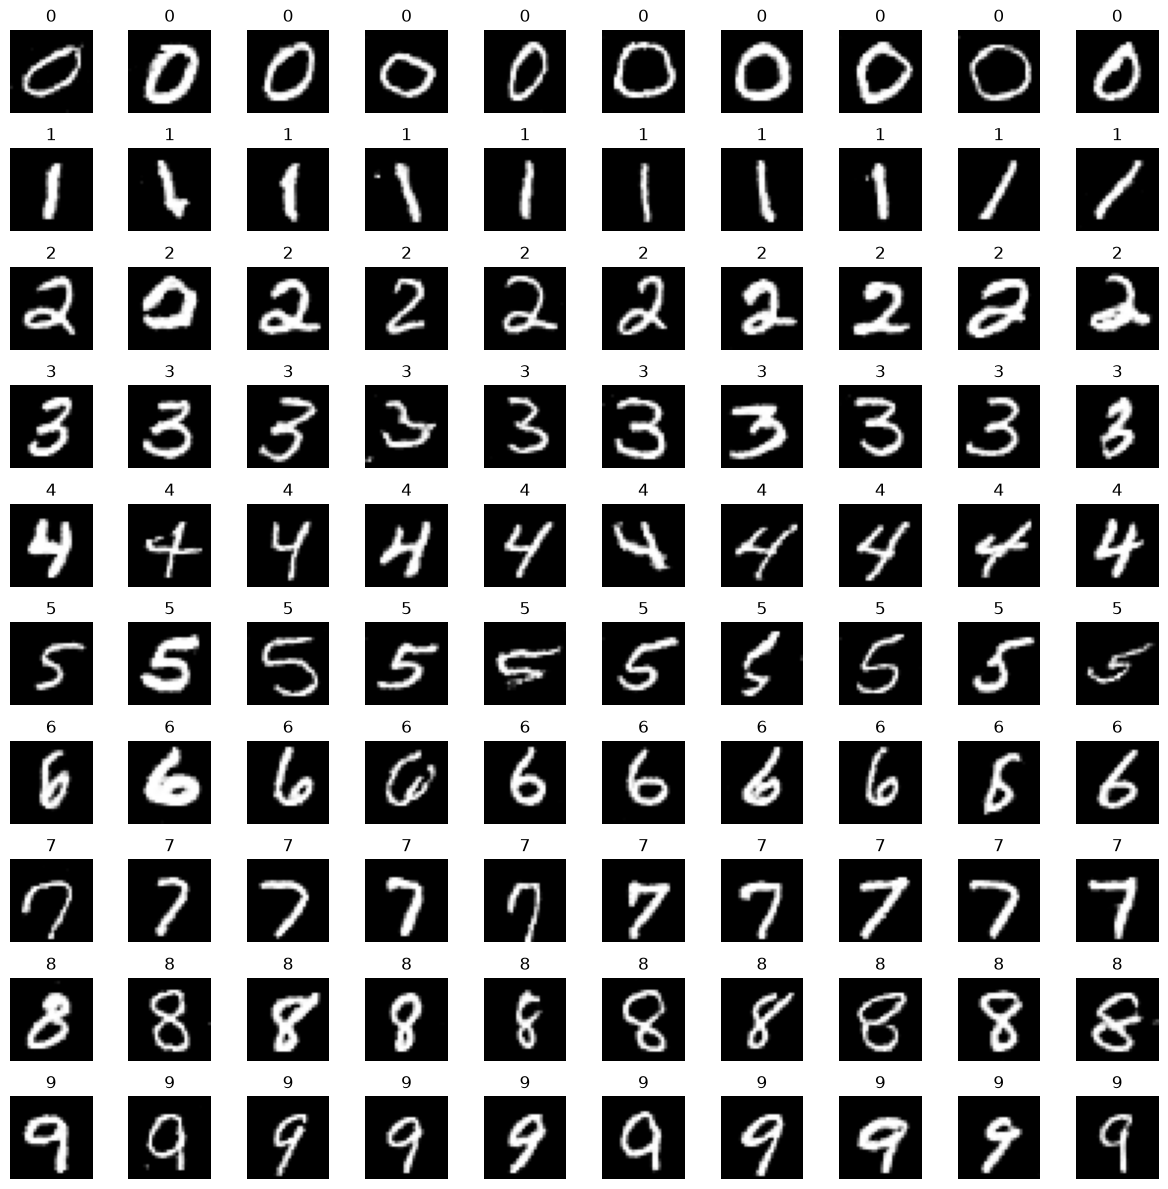

In [19]:
num_images_per_digit = 10
total_images = num_images_per_digit * num_classes

noise = tf.random.normal(shape=[total_images, randomDim])

sampled_labels = np.array([digit for digit in range(num_classes) for _ in range(num_images_per_digit)])

generated_images = generator.predict([noise, sampled_labels])

generated_images = generated_images.reshape(total_images, 28, 28)

plt.figure(figsize=(12, 12))
for i in range(total_images):
    plt.subplot(num_classes, num_images_per_digit, i + 1)
    plt.imshow(generated_images[i] * 0.5 + 0.5, cmap='gray')
    plt.title(f"{sampled_labels[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()